# 05 — Preprocessing Data Fenotipik Gabungan ABIDE I dan ABIDE II

Notebook ini melakukan audit, eksplorasi komparatif, dan pembersihan terstandarisasi data **fenotipik** gabungan **ABIDE I dan ABIDE II**, sebelum dihubungkan dengan kohort pemodelan.

| | |
| :--- | :--- |
| **Masukan** | `data/phenotypic/Phenotypic_V1_0b.csv` (ABIDE I mentah, 1.112 subjek) · `data/phenotypic/Phenotypic_ABIDE2_raw.csv` (ABIDE II mentah, 1.007 subjek, dibuat di notebook 04 dari 16 berkas `participants.tsv`) · `data/processed/kohort_dcan.csv` (hanya untuk verifikasi) |
| **Keluaran** | `data/phenotypic/phenotypic_gabungan_clean.csv` (2.119 subjek: dataset, sub_id, situs, label, usia, jenis_kelamin, fiq) |

Langkah:
1. **Pemuatan data mentah**: ABIDE I (1.112 subjek, 20 situs) dan ABIDE II (1.007 subjek, 16 situs), total 2.119 subjek.
2. **Karakterisasi multi-situs**: persebaran subjek dan rasio diagnosis (ASD vs Kontrol) per situs.
3. **Audit nilai kosong**: ABIDE I memakai kode `-9999`, ABIDE II hanya sel kosong.
4. **Pencegahan kebocoran label**: tes klinis autisme (ADOS, ADI-R, SRS) tidak dipakai sebagai fitur. Pola pengisiannya dibuktikan dengan data.
5. **Demografi komparatif**: usia, jenis kelamin, dan FIQ di kedua dataset.
6. **Penyeragaman, ekspor, dan verifikasi**: kolom diseragamkan lalu disimpan, kemudian dicocokkan per subjek dengan `kohort_dcan.csv`, yaitu data yang benar-benar dipakai S1–S4.

Pengisian nilai FIQ yang kosong **tidak** dilakukan di sini. Supaya tidak bocor, pengisian dilakukan di dalam setiap fold (median data latih) di notebook skenario S3–S4.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")

# Setup direktori kerja
ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent

PHENO_DIR = ROOT / "data" / "phenotypic"
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "result" / "figure"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Lokasi berkas input
PATH_A1_RAW = PHENO_DIR / "Phenotypic_V1_0b.csv"
PATH_A2_RAW = PHENO_DIR / "Phenotypic_ABIDE2_raw.csv"
PATH_KOHORT_DCAN = PROC_DIR / "kohort_dcan.csv"

print("=" * 65)
print("=== SETUP DIREKTORI & VERIFIKASI DATA FENOTIPIK ===")
print("=" * 65)
print(f"Direktori Fenotipik : {PHENO_DIR}")
print(f"File Raw ABIDE I    : {PATH_A1_RAW.name} (Exists: {PATH_A1_RAW.exists()})")
print(f"File Raw ABIDE II   : {PATH_A2_RAW.name} (Exists: {PATH_A2_RAW.exists()})")
print(f"File Kohort DCAN    : {PATH_KOHORT_DCAN.name} (Exists: {PATH_KOHORT_DCAN.exists()})")
print("-" * 65)


=== SETUP DIREKTORI & VERIFIKASI DATA FENOTIPIK ===
Direktori Fenotipik : C:\Users\hikma\Documents\Tugas Akhir\v7\data\phenotypic
File Raw ABIDE I    : Phenotypic_V1_0b.csv (Exists: True)
File Raw ABIDE II   : Phenotypic_ABIDE2_raw.csv (Exists: True)
File Kohort DCAN    : kohort_dcan.csv (Exists: True)
-----------------------------------------------------------------


## 1. Pemuatan Data Mentah ABIDE I & ABIDE II

Di bawah ini kita memuat berkas fenotipik mentah dari kedua dataset untuk membandingkan jumlah subjek, jumlah kolom, dan komposisi awal diagnosis sebelum dilakukan penyaringan:


In [2]:
# 1. Pemuatan Data Mentah
raw_a1 = pd.read_csv(PATH_A1_RAW)
raw_a2 = pd.read_csv(PATH_A2_RAW)

# 2. Ringkasan Komposisi Awal
ringkas_muat = pd.DataFrame({
    "Dataset": ["ABIDE I", "ABIDE II", "Total Gabungan Mentah"],
    "Total Subjek": [len(raw_a1), len(raw_a2), len(raw_a1) + len(raw_a2)],
    "Jumlah Situs": [raw_a1["SITE_ID"].nunique(), raw_a2["site_id"].nunique(), raw_a1["SITE_ID"].nunique() + raw_a2["site_id"].nunique()],
    "Jumlah Kolom Metadata": [raw_a1.shape[1], raw_a2.shape[1], "348 (ABIDE II) / 75 (ABIDE I)"],
    "Subjek ASD (Raw)": [
        int((raw_a1["DX_GROUP"] == 1).sum()),
        int((raw_a2["dx_group"] == 1).sum()),
        int((raw_a1["DX_GROUP"] == 1).sum() + (raw_a2["dx_group"] == 1).sum())
    ],
    "Subjek Kontrol (Raw)": [
        int((raw_a1["DX_GROUP"] == 2).sum()),
        int((raw_a2["dx_group"] == 2).sum()),
        int((raw_a1["DX_GROUP"] == 2).sum() + (raw_a2["dx_group"] == 2).sum())
    ],
    "Rasio ASD (%)": [
        round((raw_a1["DX_GROUP"] == 1).mean() * 100, 1),
        round((raw_a2["dx_group"] == 1).mean() * 100, 1),
        round(((raw_a1["DX_GROUP"] == 1).sum() + (raw_a2["dx_group"] == 1).sum()) / (len(raw_a1) + len(raw_a2)) * 100, 1)
    ]
})

display(ringkas_muat.style.set_caption("Tabel 1: Ringkasan Metadata Mentah ABIDE I vs ABIDE II (Sebelum Filter)"))


,Dataset,Total Subjek,Jumlah Situs,Jumlah Kolom Metadata,Subjek ASD (Raw),Subjek Kontrol (Raw),Rasio ASD (%)
0,ABIDE I,1112,20,75,539,573,48.500000
1,ABIDE II,1007,16,348,474,533,47.100000
2,Total Gabungan Mentah,2119,36,348 (ABIDE II) / 75 (ABIDE I),1013,1106,47.800000


## 2. Analisis Heterogenitas Multi-Situs: Sebaran Subjek & Proporsi Diagnosis

Dataset ABIDE dikumpulkan dari berbagai institusi riset independen di seluruh dunia. Variasi jumlah subjek dan keseimbangan diagnosis antar-situs merupakan faktor krusial yang mempengaruhi generalisasi model kecerdasan buatan.

Tabel dan visualisasi di bawah memetakan sebaran seluruh **20 situs ABIDE I** dan **16 situs ABIDE II**:


,Total,ASD,Kontrol,Proporsi ASD (%)
SITE_ID,,,,
NYU,184,79,105,42.900000
UM_1,110,55,55,50.000000
USM,101,58,43,57.400000
UCLA_1,82,49,33,59.800000
PITT,57,30,27,52.600000
MAX_MUN,57,24,33,42.100000
YALE,56,28,28,50.000000
KKI,55,22,33,40.000000
TRINITY,49,24,25,49.000000


,Total,ASD,Kontrol,Proporsi ASD (%)
site_id,,,,
ABIDEII-KKI_1,211,56,155,26.500000
ABIDEII-GU_1,106,51,55,48.100000
ABIDEII-OHSU_1,93,37,56,39.800000
ABIDEII-NYU_1,78,48,30,61.500000
ABIDEII-ONRC_2,59,24,35,40.700000
ABIDEII-SDSU_1,58,33,25,56.900000
ABIDEII-BNI_1,58,29,29,50.000000
ABIDEII-IP_1,56,22,34,39.300000
ABIDEII-EMC_1,54,27,27,50.000000


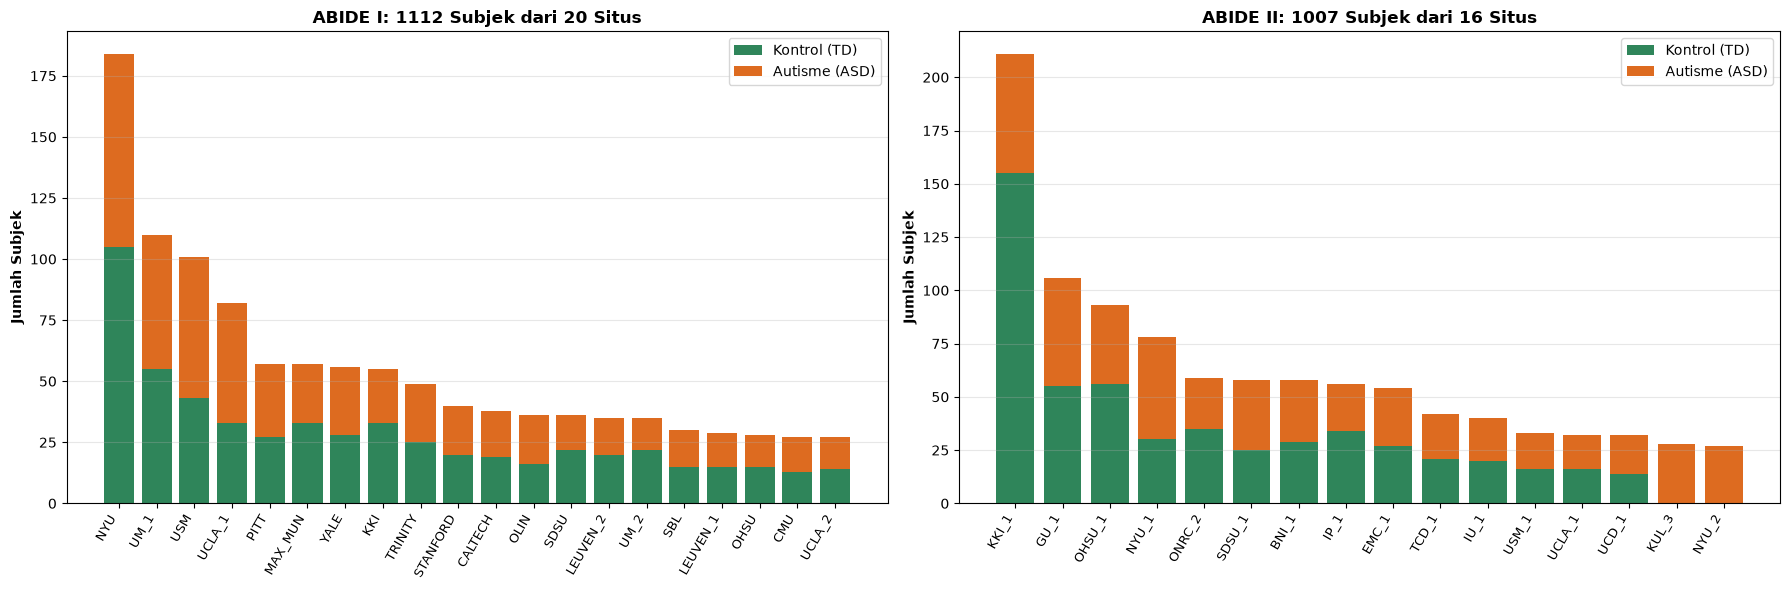

In [3]:
# 1. Agregasi per situs untuk ABIDE I
situs_a1 = raw_a1.groupby("SITE_ID").agg(
    Total=("DX_GROUP", "size"),
    ASD=("DX_GROUP", lambda s: (s == 1).sum()),
    Kontrol=("DX_GROUP", lambda s: (s == 2).sum())
).sort_values("Total", ascending=False)
situs_a1["Proporsi ASD (%)"] = (situs_a1["ASD"] / situs_a1["Total"] * 100).round(1)

# 2. Agregasi per situs untuk ABIDE II
situs_a2 = raw_a2.groupby("site_id").agg(
    Total=("dx_group", "size"),
    ASD=("dx_group", lambda s: (s == 1).sum()),
    Kontrol=("dx_group", lambda s: (s == 2).sum())
).sort_values("Total", ascending=False)
situs_a2["Proporsi ASD (%)"] = (situs_a2["ASD"] / situs_a2["Total"] * 100).round(1)

# Tampilkan ringkasan tabel
display(situs_a1.style.set_caption(f"Tabel 2a: Distribusi 20 Situs ABIDE I (Total {len(raw_a1)} Subjek)"))
display(situs_a2.style.set_caption(f"Tabel 2b: Distribusi 16 Situs ABIDE II (Total {len(raw_a2)} Subjek)"))

# 3. Visualisasi Grafik Komparasi Sebaran Situs
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot Kiri: ABIDE I
x1 = np.arange(len(situs_a1))
axes[0].bar(x1, situs_a1["Kontrol"], color="#2F855A", label="Kontrol (TD)")
axes[0].bar(x1, situs_a1["ASD"], bottom=situs_a1["Kontrol"], color="#DD6B20", label="Autisme (ASD)")
axes[0].set_xticks(x1)
axes[0].set_xticklabels(situs_a1.index, rotation=60, ha="right", fontsize=9)
axes[0].set_ylabel("Jumlah Subjek", fontweight="bold")
axes[0].set_title(f"ABIDE I: {len(raw_a1)} Subjek dari {len(situs_a1)} Situs", fontweight="bold")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Plot Kanan: ABIDE II
x2 = np.arange(len(situs_a2))
lbls_a2 = [s.replace("ABIDEII-", "") for s in situs_a2.index]
axes[1].bar(x2, situs_a2["Kontrol"], color="#2F855A", label="Kontrol (TD)")
axes[1].bar(x2, situs_a2["ASD"], bottom=situs_a2["Kontrol"], color="#DD6B20", label="Autisme (ASD)")
axes[1].set_xticks(x2)
axes[1].set_xticklabels(lbls_a2, rotation=60, ha="right", fontsize=9)
axes[1].set_ylabel("Jumlah Subjek", fontweight="bold")
axes[1].set_title(f"ABIDE II: {len(raw_a2)} Subjek dari {len(situs_a2)} Situs", fontweight="bold")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(FIG_DIR / "02b_1_sebaran_situs_abide1_abide2.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Audit Nilai Hilang (*Missing Values*) & Penanganan Format Khusus

| Dataset | Bentuk nilai kosong |
| :--- | :--- |
| ABIDE I | sel kosong **atau kode `-9999`** (subjek tidak menjalani tes tertentu) |
| ABIDE II | sel kosong saja. Pemeriksaan di notebook 04: tidak ada kode `-9999` dan tidak ada IQ ≤ 0 |

Standarisasi yang dilakukan:
1. mengubah semua `-9999` menjadi `NaN`, dan nilai IQ ≤ 0 (tidak mungkin terjadi) menjadi `NaN`. Aturan yang sama diterapkan ke kedua dataset supaya seragam;
2. menghitung persentase nilai kosong kolom demografi dan kognitif utama.

In [4]:
# 1. Konversi Format Missing Values ABIDE I
df1_clean = raw_a1.copy()
cols1_target = ["AGE_AT_SCAN", "SEX", "FIQ", "VIQ", "PIQ", "HANDEDNESS_CATEGORY"]
for col in cols1_target:
    df1_clean[col] = df1_clean[col].replace(-9999, np.nan)
    if col in ["FIQ", "VIQ", "PIQ"]:
        df1_clean[col] = df1_clean[col].where(df1_clean[col] > 0)

# 2. Konversi Format Missing Values ABIDE II
df2_clean = raw_a2.copy()
cols2_target = ["age_at_scan", "sex", "fiq", "viq", "piq", "handedness_category"]
for col in cols2_target:
    df2_clean[col] = df2_clean[col].replace(-9999, np.nan)
    if col in ["fiq", "viq", "piq"]:
        df2_clean[col] = df2_clean[col].where(df2_clean[col] > 0)

# 3. Rekapitulasi Audit Missing Values
audit_missing = pd.DataFrame({
    "Variabel": ["Usia (Age)", "Jenis Kelamin (Sex)", "Full-Scale IQ (FIQ)", "Verbal IQ (VIQ)", "Performance IQ (PIQ)", "Handedness"],
    "Kosong ABIDE I (N=1112)": [
        f"{df1_clean['AGE_AT_SCAN'].isna().sum()} ({df1_clean['AGE_AT_SCAN'].isna().mean()*100:.1f}%)",
        f"{df1_clean['SEX'].isna().sum()} ({df1_clean['SEX'].isna().mean()*100:.1f}%)",
        f"{df1_clean['FIQ'].isna().sum()} ({df1_clean['FIQ'].isna().mean()*100:.1f}%)",
        f"{df1_clean['VIQ'].isna().sum()} ({df1_clean['VIQ'].isna().mean()*100:.1f}%)",
        f"{df1_clean['PIQ'].isna().sum()} ({df1_clean['PIQ'].isna().mean()*100:.1f}%)",
        f"{df1_clean['HANDEDNESS_CATEGORY'].isna().sum()} ({df1_clean['HANDEDNESS_CATEGORY'].isna().mean()*100:.1f}%)"
    ],
    "Kosong ABIDE II (N=1007)": [
        f"{df2_clean['age_at_scan'].isna().sum()} ({df2_clean['age_at_scan'].isna().mean()*100:.1f}%)",
        f"{df2_clean['sex'].isna().sum()} ({df2_clean['sex'].isna().mean()*100:.1f}%)",
        f"{df2_clean['fiq'].isna().sum()} ({df2_clean['fiq'].isna().mean()*100:.1f}%)",
        f"{df2_clean['viq'].isna().sum()} ({df2_clean['viq'].isna().mean()*100:.1f}%)",
        f"{df2_clean['piq'].isna().sum()} ({df2_clean['piq'].isna().mean()*100:.1f}%)",
        f"{df2_clean['handedness_category'].isna().sum()} ({df2_clean['handedness_category'].isna().mean()*100:.1f}%)"
    ]
})

display(audit_missing.style.set_caption("Tabel 3: Evaluasi Persentase Missing Values Kolom Fenotipik Utama"))


,Variabel,Kosong ABIDE I (N=1112),Kosong ABIDE II (N=1007)
0,Usia (Age),0 (0.0%),0 (0.0%)
1,Jenis Kelamin (Sex),0 (0.0%),0 (0.0%)
2,Full-Scale IQ (FIQ),72 (6.5%),98 (9.7%)
3,Verbal IQ (VIQ),195 (17.5%),315 (31.3%)
4,Performance IQ (PIQ),181 (16.3%),242 (24.0%)
5,Handedness,315 (28.3%),23 (2.3%)


## 4. Skrining Kolom Ilmiah & Pencegahan Kebocoran Data (*Data Leakage*)

Ada tiga instrumen klinis autisme di data fenotipik. Ketiganya **tidak dipakai sebagai fitur**, tetapi alasannya berbeda:

| Instrumen | Apa yang diukur | Pola pengisian | Alasan dibuang |
| :--- | :--- | :--- | :--- |
| **ADOS** (*Autism Diagnostic Observation Schedule*) | observasi klinis untuk **menegakkan diagnosis** | hampir hanya diisi untuk subjek ASD | **kebocoran label langsung**: sekadar "ada atau tidaknya" skor ADOS sudah hampir menebak diagnosis |
| **ADI-R** (*Autism Diagnostic Interview-Revised*) | wawancara klinis untuk **menegakkan diagnosis** | hampir hanya diisi untuk subjek ASD | sama dengan ADOS |
| **SRS** (*Social Responsiveness Scale*) | kuesioner **tingkat gejala autisme** | diisi untuk ASD **dan** Kontrol | **kebocoran label tidak langsung**: nilainya adalah ukuran autisme itu sendiri, bukan ciri otak. Tujuan penelitian adalah mendeteksi ASD dari citra otak |

Tabel di bawah dihitung langsung dari data, tidak diketik manual.

In [5]:
# Pola pengisian tes klinis autisme pada ASD vs Kontrol (dihitung dari data)
INSTRUMEN = [("ADOS total", "ABIDE I", df1_clean, "ADOS_TOTAL", "DX_GROUP"),
             ("ADOS-2 total", "ABIDE II", df2_clean, "ados_2_total", "dx_group"),
             ("ADI-R sosial", "ABIDE I", df1_clean, "ADI_R_SOCIAL_TOTAL_A", "DX_GROUP"),
             ("ADI-R sosial", "ABIDE II", df2_clean, "adi_r_social_total_a", "dx_group"),
             ("SRS total", "ABIDE I", df1_clean, "SRS_RAW_TOTAL", "DX_GROUP"),
             ("SRS total", "ABIDE II", df2_clean, "srs_total_raw", "dx_group")]
baris = []
for nama, ds, df, kol, dx in INSTRUMEN:
    nilai = pd.to_numeric(df[kol], errors="coerce").replace(-9999, np.nan)
    terisi = nilai > 0
    asd, kon = df[dx] == 1, df[dx] == 2
    baris.append({"Instrumen": nama, "Dataset": ds,
                  "Terisi pada ASD": f"{int(terisi[asd].sum())} dari {int(asd.sum())} ({terisi[asd].mean() * 100:.1f}%)",
                  "Terisi pada Kontrol": f"{int(terisi[kon].sum())} dari {int(kon.sum())} ({terisi[kon].mean() * 100:.1f}%)",
                  "Dari yang terisi, milik ASD (%)": round(terisi[asd].sum() / max(terisi.sum(), 1) * 100, 1)})
bukti_leakage = pd.DataFrame(baris)
bukti_leakage["Keputusan"] = np.where(bukti_leakage["Instrumen"].str.startswith("SRS"),
                                      "dibuang (mengukur gejala autisme)", "dibuang (instrumen diagnosis)")
display(bukti_leakage.style.set_caption("Tabel 4: Pola pengisian tes klinis autisme (dihitung dari data)"))

,Instrumen,Dataset,Terisi pada ASD,Terisi pada Kontrol,"Dari yang terisi, milik ASD (%)",Keputusan
0,ADOS total,ABIDE I,383 dari 539 (71.1%),19 dari 573 (3.3%),95.300000,dibuang (instrumen diagnosis)
1,ADOS-2 total,ABIDE II,233 dari 474 (49.2%),2 dari 533 (0.4%),99.100000,dibuang (instrumen diagnosis)
2,ADI-R sosial,ABIDE I,378 dari 539 (70.1%),0 dari 573 (0.0%),100.000000,dibuang (instrumen diagnosis)
3,ADI-R sosial,ABIDE II,288 dari 474 (60.8%),0 dari 533 (0.0%),100.000000,dibuang (instrumen diagnosis)
4,SRS total,ABIDE I,190 dari 539 (35.3%),172 dari 573 (30.0%),52.500000,dibuang (mengukur gejala autisme)
5,SRS total,ABIDE II,367 dari 474 (77.4%),384 dari 533 (72.0%),48.900000,dibuang (mengukur gejala autisme)


## 5. Distribusi Demografi Komparatif: Usia, Jenis Kelamin, dan FIQ

Tiga variabel fenotipik non-bocor yang dipertahankan sebagai fitur komplementer bagi model Graph Neural Network (GNN) adalah:
1. **Usia (*Age*)**: Usia perkembangan mempengaruhi konektivitas fungsional kortikal.
2. **Jenis Kelamin (*Sex*)**: Rasio prevalensi autisme lebih tinggi pada laki-laki.
3. **Full-Scale IQ (*FIQ*)**: Mengontrol tingkat intelegensi umum subjek.

Grafik di bawah membandingkan distribusi ketiga variabel tersebut antara ABIDE I dan ABIDE II:


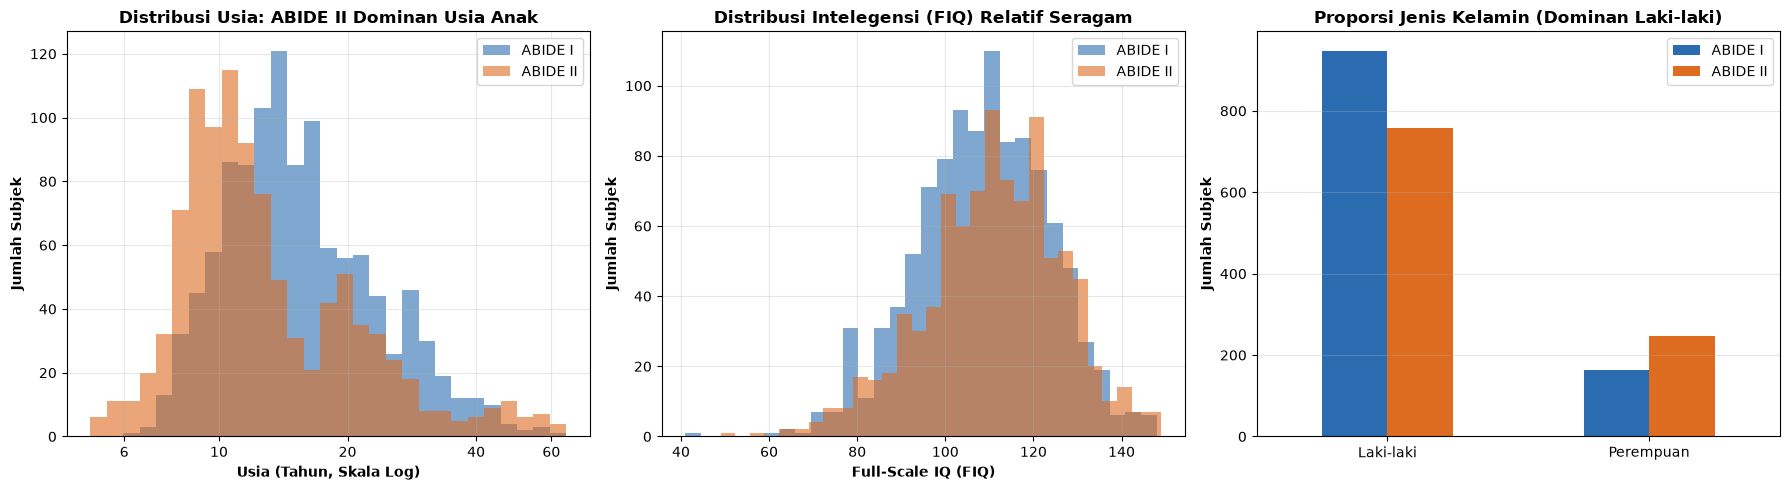

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribusi Usia (Skala Logaritmik)
for df_sub, w, lbl in [(df1_clean, "#2B6CB0", "ABIDE I"), (df2_clean, "#DD6B20", "ABIDE II")]:
    age_col = "AGE_AT_SCAN" if "AGE_AT_SCAN" in df_sub.columns else "age_at_scan"
    axes[0].hist(df_sub[age_col].dropna(), bins=np.logspace(np.log10(5), np.log10(65), 30), alpha=0.6, color=w, label=lbl)

axes[0].set_xscale("log")
axes[0].set_xticks([6, 10, 20, 40, 60])
axes[0].set_xticklabels(["6", "10", "20", "40", "60"])
axes[0].minorticks_off()
axes[0].set_xlabel("Usia (Tahun, Skala Log)", fontweight="bold")
axes[0].set_ylabel("Jumlah Subjek", fontweight="bold")
axes[0].set_title("Distribusi Usia: ABIDE II Dominan Usia Anak", fontweight="bold")
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2. Distribusi Skor FIQ
for df_sub, w, lbl in [(df1_clean, "#2B6CB0", "ABIDE I"), (df2_clean, "#DD6B20", "ABIDE II")]:
    fiq_col = "FIQ" if "FIQ" in df_sub.columns else "fiq"
    axes[1].hist(df_sub[fiq_col].dropna(), bins=30, alpha=0.6, color=w, label=lbl)

axes[1].set_xlabel("Full-Scale IQ (FIQ)", fontweight="bold")
axes[1].set_ylabel("Jumlah Subjek", fontweight="bold")
axes[1].set_title("Distribusi Intelegensi (FIQ) Relatif Seragam", fontweight="bold")
axes[1].legend()
axes[1].grid(alpha=0.3)

# 3. Proporsi Jenis Kelamin (Laki-laki vs Perempuan)
sex_data = pd.DataFrame({
    "ABIDE I": [(df1_clean["SEX"] == 1).sum(), (df1_clean["SEX"] == 2).sum()],
    "ABIDE II": [(df2_clean["sex"] == 1).sum(), (df2_clean["sex"] == 2).sum()]
}, index=["Laki-laki", "Perempuan"])

sex_data.plot(kind="bar", ax=axes[2], color=["#2B6CB0", "#DD6B20"], rot=0)
axes[2].set_ylabel("Jumlah Subjek", fontweight="bold")
axes[2].set_title("Proporsi Jenis Kelamin (Dominan Laki-laki)", fontweight="bold")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(FIG_DIR / "02b_2_distribusi_demografi_abide1_abide2.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Standarisasi, Ekspor, dan Verifikasi

Langkah:
1. **Menyeragamkan kolom** kedua dataset: `dataset`, `sub_id`, `situs`, `label` (1 = ASD, 0 = Kontrol), `usia`, `jenis_kelamin` (1 = laki-laki, 2 = perempuan), `fiq`.
2. **FIQ yang kosong dibiarkan kosong.** Kalau median dihitung dari seluruh 2.119 subjek di sini, median itu ikut memakai subjek yang nanti menjadi data uji, dan itu termasuk kebocoran. Pengisian dilakukan di dalam setiap fold dari median **data latih** saja (notebook skenario S3–S4), disertai penanda "FIQ kosong".
3. **Menyimpan** ke `data/phenotypic/phenotypic_gabungan_clean.csv`.
4. **Verifikasi sungguhan** terhadap `data/processed/kohort_dcan.csv` (1.638 subjek yang dipakai S1–S4): setiap subjek di kohort dicari di tabel ini, lalu label, usia, jenis kelamin, FIQ, dan situsnya dibandingkan satu per satu.
5. **Alur jumlah subjek** dari 2.119 sampai 1.638.

In [7]:
# 1. Standarisasi ABIDE I
df1_std = pd.DataFrame({
    "dataset": "abide1",
    "sub_id": df1_clean["SUB_ID"].astype(str),
    "situs": df1_clean["SITE_ID"],
    "label": df1_clean["DX_GROUP"].map({1: 1, 2: 0}),  # 1=ASD, 0=Kontrol
    "usia": df1_clean["AGE_AT_SCAN"],
    "jenis_kelamin": df1_clean["SEX"],                 # 1=Laki-laki, 2=Perempuan
    "fiq": df1_clean["FIQ"],
})

# 2. Standarisasi ABIDE II
df2_std = pd.DataFrame({
    "dataset": "abide2",
    "sub_id": df2_clean["participant_id"].astype(str),
    "situs": df2_clean["site_id"],
    "label": df2_clean["dx_group"].map({1: 1, 2: 0}),  # 1=ASD, 0=Kontrol
    "usia": df2_clean["age_at_scan"],
    "jenis_kelamin": df2_clean["sex"],                 # 1=Laki-laki, 2=Perempuan
    "fiq": df2_clean["fiq"],
})

# 3. Penggabungan (FIQ kosong dibiarkan kosong; diisi di dalam fold pada notebook S3–S4)
df_gabung = pd.concat([df1_std, df2_std], ignore_index=True)

# 4. Ekspor
out_clean_path = PHENO_DIR / "phenotypic_gabungan_clean.csv"
df_gabung.to_csv(out_clean_path, index=False)
display(pd.DataFrame({
    "Dataset": ["ABIDE I", "ABIDE II", "Total"],
    "Subjek": [int((df_gabung["dataset"] == d).sum()) for d in ("abide1", "abide2")] + [len(df_gabung)],
    "ASD": [int(((df_gabung["dataset"] == d) & (df_gabung["label"] == 1)).sum()) for d in ("abide1", "abide2")] + [int((df_gabung["label"] == 1).sum())],
    "Kontrol": [int(((df_gabung["dataset"] == d) & (df_gabung["label"] == 0)).sum()) for d in ("abide1", "abide2")] + [int((df_gabung["label"] == 0).sum())],
    "FIQ kosong (%)": [round(df_gabung.loc[df_gabung["dataset"] == d, "fiq"].isna().mean() * 100, 1) for d in ("abide1", "abide2")]
                      + [round(df_gabung["fiq"].isna().mean() * 100, 1)],
}).style.set_caption(f"Disimpan: {out_clean_path.name}"))

# 5. Verifikasi per subjek terhadap kohort_dcan.csv (data yang dipakai S1–S4)
kohort_dcan = pd.read_csv(PATH_KOHORT_DCAN)
kunci = kohort_dcan.assign(sub_id=np.where(kohort_dcan["dataset"] == "abide1",
                                           kohort_dcan["FILE_ID"].str.split("_").str[-1].str.lstrip("0"),
                                           kohort_dcan["sub"].str.replace("sub-", "")))
gab = df_gabung.assign(sub_id=df_gabung["sub_id"].str.lstrip("0"))
cocok = kunci.merge(gab, on=["dataset", "sub_id"], how="left", suffixes=("_kohort", "_02b"))
verifikasi = []
for kol in ["label", "usia", "jenis_kelamin", "fiq"]:
    a, b = cocok[f"{kol}_kohort"].astype(float), cocok[f"{kol}_02b"].astype(float)
    sama = np.isclose(a, b) | (a.isna() & b.isna())
    verifikasi.append({"Kolom": kol, "Subjek sama": int(sama.sum()), "Subjek berbeda": int((~sama).sum())})
situs_sama = cocok["situs_kohort"].str.upper().str.replace("ABIDEII-", "") == cocok["situs_02b"].str.upper().str.replace("ABIDEII-", "")
verifikasi.append({"Kolom": "situs", "Subjek sama": int(situs_sama.sum()), "Subjek berbeda": int((~situs_sama).sum())})
verifikasi = pd.DataFrame(verifikasi)
display(verifikasi.style.set_caption(f"Verifikasi: {int(cocok['label_02b'].notna().sum())} dari {len(kohort_dcan)} subjek kohort ditemukan di tabel ini"))
assert cocok["label_02b"].notna().all() and (verifikasi["Subjek berbeda"] == 0).all(), "ada subjek kohort yang tidak cocok dengan tabel fenotipik!"
print("✓ Semua subjek kohort_dcan.csv cocok dengan hasil notebook ini (label, usia, jenis kelamin, FIQ, situs).")

# 6. Alur jumlah subjek: 2.119 -> 1.638 (tahap-tahap dikerjakan di notebook kohort ABIDE I dan notebook 21)
alur = pd.read_csv(ROOT / "result" / "tabel" / "21_alur_kohort_dcan.csv")
alur_lengkap = pd.concat([pd.DataFrame([{"Kriteria (kumulatif)": "Fenotipik mentah (notebook ini)", "ABIDE I": len(df1_std),
                                         "ABIDE II": len(df2_std), "Total": len(df_gabung)}]), alur.iloc[:, :4]], ignore_index=True)
alur_lengkap.loc[1, "Kriteria (kumulatif)"] = "ABIDE I: lolos seleksi kohort ABIDE I (987 subjek); ABIDE II: punya fenotipik"
display(alur_lengkap.style.set_caption("Alur jumlah subjek dari data mentah sampai kohort akhir"))

,Dataset,Subjek,ASD,Kontrol,FIQ kosong (%)
0,ABIDE I,1112,539,573,6.500000
1,ABIDE II,1007,474,533,9.700000
2,Total,2119,1013,1106,8.000000


,Kolom,Subjek sama,Subjek berbeda
0,label,1638,0
1,usia,1638,0
2,jenis_kelamin,1638,0
3,fiq,1638,0
4,situs,1638,0


✓ Semua subjek kohort_dcan.csv cocok dengan hasil notebook ini (label, usia, jenis kelamin, FIQ, situs).


,Kriteria (kumulatif),ABIDE I,ABIDE II,Total
0,Fenotipik mentah (notebook ini),1112,1007,2119
1,ABIDE I: lolos seleksi kohort ABIDE I (987 subjek); ABIDE II: punya fenotipik,987,1007,1994
2,Time series DCAN 3 atlas lengkap dan valid,979,928,1907
3,"Bukan situs satu kelas (KUL_3, NYU_2)",979,873,1852
4,"QC gerakan: FD < 0.3 mm, sisa ≥ 180 detik",886,752,1638


## 7. Kesimpulan Preprocessing Fenotipik Gabungan

1. **Data gabungan: 2.119 subjek mentah**, terdiri dari ABIDE I (1.112 subjek, 20 situs) dan ABIDE II (1.007 subjek, 16 situs). Setelah seleksi kohort ABIDE I (987 subjek) dan kriteria notebook 09 (data DCAN lengkap, bukan situs satu kelas, QC gerakan), tersisa **1.638 subjek**.
2. **Kebocoran label dicegah.** ADOS dan ADI-R adalah instrumen diagnosis dan hampir hanya terisi untuk ASD. SRS terisi untuk kedua kelompok, tetapi mengukur gejala autisme itu sendiri. Ketiganya tidak dipakai sebagai fitur.
3. **Tiga fitur fenotipik** (`usia`, `jenis_kelamin`, `fiq`) diseragamkan. FIQ yang kosong (±8%) **tidak diisi di sini**, melainkan di dalam setiap fold dari median data latih, supaya tidak bocor.
4. **Terverifikasi:** label, usia, jenis kelamin, FIQ, dan situs dari notebook ini **identik** dengan `kohort_dcan.csv` untuk ke-1.638 subjek yang dipakai S1–S4.
5. Di model, fitur fenotipik masuk lewat **cabang fenotipik tersendiri** (MLP kecil) yang digabung dengan cabang graf dan cabang linear melalui fusi atensi (Skenario 3 dan 4). Fenotipik bukan atribut simpul graf.

---

### Peta Keterhubungan Notebook

```
01 / 01b  ──► Pemahaman data citra mentah (raw NIfTI) & turunan DCAN
02 / 02a  ──► EDA fenotipik ABIDE I / ABIDE II
02b       ──► Preprocessing & standarisasi fenotipik gabungan ABIDE I + II (notebook ini)
21        ──► Kohort akhir: data DCAN lengkap, situs satu kelas, QC gerakan → 1.638 subjek, 5 fold
22 / 23   ──► FC tangent (rs-fMRI) & morfometri, MIND, kopling (sMRI)
25–28     ──► Skenario S1–S4
```